# Isotropic plate with an offset

A skin modelled on its mould line, or a plate whose nodes are not on its
mid-surface, has its reference surface away from the mid-surface. This
example creates an isotropic plate with `isotropic_plate` and an offset
$d$, the position of the mid-surface relative to the reference surface, see
[Conventions](../conventions.rst), and compares every thickness integral of
the `Laminate` with its closed form: the matrices $A$, $B$, $D$ of the CLPT,
the transverse shear stiffness of the FSDT, the matrices $E$, $F$, $H$ of the
TSDT and the moments of the density used in the mass matrices. SI units are
used throughout.

## The closed form

With the same plane-stress stiffness $C$ in the whole thickness, the
integrals of [Laminate stiffness and plate theories](../constitutive_matrices.rst),

$$
(A, B, D, E, F, H) = C \int_{d - h/2}^{d + h/2} (1, z, z^2, z^3, z^4, z^6)
\, dz,
$$

are moments of $z$. Writing $z = d + s$, with $s$ uniform in $[-h/2, h/2]$,
$\int (d + s)^n ds = h \langle (d + s)^n \rangle$, where the odd moments of
$s$ vanish and $\langle s^2 \rangle = h^2/12$, $\langle s^4 \rangle = h^4/80$,
$\langle s^6 \rangle = h^6/448$:

$$
A = h C, \qquad B = d h C, \qquad D = h \left( d^2 + \frac{h^2}{12}
\right) C.
$$

This is the shift of the reference surface of Vasiliev and Morozov [1], Eq.
(5.28), $B = B^0 + d A$ and $D = D^0 + 2 d B^0 + d^2 A$, with $B^0 = 0$ and
$D^0 = h^3 C/12$ about the mid-surface. The offset creates a membrane-bending
coupling $B \neq 0$ in a plate that has none about its mid-surface.

The transverse shear stiffness $\bar{A}_{ts} = G h I$ does not depend on the
reference surface. For a homogeneous plate the equilibrium distribution is the
parabola $\tau_{xz} = 3 Q_x/(2h) (1 - 4 \bar{z}^2/h^2)$, $\bar{z}$ measured from
the mid-surface, whose complementary energy $3 Q_x^2/(5 G h)$ equals the
energy $Q_x^2/(2 \kappa G h)$ of a constant distribution for $\kappa = 5/6$,
see [Shear correction](../shear_correction.rst). Rohwer [2], Sec. 4.1, p. 17,
states that this ratio "always amounts to 5/6, independent of the Poisson's
ratio or the position of the reference surface", hence
$A_{ts} = \frac{5}{6} G h I$ also with an offset.

`print_table` prints a result, its reference and the relative difference;
for a reference equal to zero the difference is divided by a scale given in
the row.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from composites import isotropic_plate

def print_table(rows):
    """Print each result, its reference value and their relative difference

    ``rows`` holds ``(name, value, reference)`` or ``(name, value, reference,
    scale)``; the difference is divided by ``scale``, by default the absolute
    value of the reference, e.g. the largest term of the matrix when the
    reference is zero.
    """
    print('%-36s %14s %14s %10s' % ('quantity', 'composites', 'reference',
                                    'rel. diff.'))
    for row in rows:
        name, value, ref = row[:3]
        scale = row[3] if len(row) > 3 else abs(ref)
        print('%-36s % 14.6e % 14.6e %10.1e' % (name, value, ref,
                                               abs(value - ref)/scale))

## Stiffness matrices

An aluminium plate of 2 mm whose mid-surface is 0.6 mm above the reference
surface. The plane-stress stiffness $C$ and the shear modulus $G$ are written
here from $E$ and $\nu$; the table compares the terms of each matrix.

In [2]:
E, nu, h, d, rho = 70e9, 0.3, 2e-3, 0.6e-3, 2700.
lam = isotropic_plate(thickness=h, E=E, nu=nu, offset=d, rho=rho)
C = E/(1 - nu**2)*np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu)/2]])
G = E/(2*(1 + nu))
print('B =')
print(lam.B)
print()
print_table([
    ('A11 = h C11', lam.A11, h*C[0, 0]),
    ('A12 = h C12', lam.A12, h*C[0, 1]),
    ('A66 = h C66', lam.A66, h*C[2, 2]),
    ('B11 = d h C11', lam.B11, d*h*C[0, 0]),
    ('B12 = d h C12', lam.B12, d*h*C[0, 1]),
    ('B66 = d h C66', lam.B66, d*h*C[2, 2]),
    ('D11 = h (d^2 + h^2/12) C11', lam.D11, h*(d**2 + h**2/12)*C[0, 0]),
    ('D12 = h (d^2 + h^2/12) C12', lam.D12, h*(d**2 + h**2/12)*C[0, 1]),
    ('D66 = h (d^2 + h^2/12) C66', lam.D66, h*(d**2 + h**2/12)*C[2, 2]),
    ('A44 = 5/6 G h', lam.A44, 5/6*G*h),
    ('A55 = 5/6 G h', lam.A55, 5/6*G*h),
    ('A45 = 0 (scale G h)', lam.A45, 0., G*h),
])

B =
[[92307.69230769 27692.30769231     0.        ]
 [27692.30769231 92307.69230769     0.        ]
 [    0.             0.         32307.69230769]]

quantity                                 composites      reference rel. diff.
A11 = h C11                            1.538462e+08   1.538462e+08    0.0e+00
A12 = h C12                            4.615385e+07   4.615385e+07    0.0e+00
A66 = h C66                            5.384615e+07   5.384615e+07    1.4e-16
B11 = d h C11                          9.230769e+04   9.230769e+04    1.6e-16
B12 = d h C12                          2.769231e+04   2.769231e+04    2.6e-16
B66 = d h C66                          3.230769e+04   3.230769e+04    0.0e+00
D11 = h (d^2 + h^2/12) C11             1.066667e+02   1.066667e+02    1.3e-16
D12 = h (d^2 + h^2/12) C12             3.200000e+01   3.200000e+01    1.1e-16
D66 = h (d^2 + h^2/12) C66             3.733333e+01   3.733333e+01    0.0e+00
A44 = 5/6 G h                          4.487179e+07   4.487179e+07    

## Matrices of the TSDT and moments of the density

The higher moments follow from the same expansion,
$\langle (d + s)^3 \rangle = d^3 + d h^2/4$,
$\langle (d + s)^4 \rangle = d^4 + d^2 h^2/2 + h^4/80$ and
$\langle (d + s)^6 \rangle = d^6 + 15 d^4 h^2/12 + 15 d^2 h^4/80 + h^6/448$,
the list `m` below. They give $E = h \langle z^3 \rangle C$,
$F = h \langle z^4 \rangle C$, $H = h \langle z^6 \rangle C$, and the moments of
the density of [Mass integrals](../mass_integrals.rst),
$I_n = \int \rho z^n dz = \rho h \langle z^n \rangle$, stored as `intrho`,
`intrhoz`, `intrhoz2`, `intrhoz3`, `intrhoz4` and `intrhoz6`.

In [3]:
m = [1., d, d**2 + h**2/12, d**3 + d*h**2/4,
     d**4 + d**2*h**2/2 + h**4/80, None,
     d**6 + 15/12*d**4*h**2 + 15/80*d**2*h**4 + h**6/448]
print_table([
    ('E11 = h <z^3> C11', lam.E11, h*m[3]*C[0, 0]),
    ('F11 = h <z^4> C11', lam.F11, h*m[4]*C[0, 0]),
    ('H11 = h <z^6> C11', lam.H11, h*m[6]*C[0, 0]),
] + [('%s = rho h <z^%d>' % (name, n), getattr(lam, name), rho*h*m[n])
     for name, n in (('intrho', 0), ('intrhoz', 1), ('intrhoz2', 2),
                     ('intrhoz3', 3), ('intrhoz4', 4), ('intrhoz6', 6))])

quantity                                 composites      reference rel. diff.
E11 = h <z^3> C11                      1.255385e-01   1.255385e-01    2.2e-16
F11 = h <z^4> C11                      1.614769e-04   1.614769e-04    1.7e-16
H11 = h <z^6> C11                      2.950020e-10   2.950020e-10    5.3e-16
intrho = rho h <z^0>                   5.400000e+00   5.400000e+00    0.0e+00
intrhoz = rho h <z^1>                  3.240000e-03   3.240000e-03    1.3e-16
intrhoz2 = rho h <z^2>                 3.744000e-06   3.744000e-06    2.3e-16
intrhoz3 = rho h <z^3>                 4.406400e-09   4.406400e-09    3.8e-16
intrhoz4 = rho h <z^4>                 5.667840e-12   5.667840e-12    1.4e-16
intrhoz6 = rho h <z^6>                 1.035457e-17   1.035457e-17    4.5e-16


## Dependence on the offset

$B$ grows linearly and $D$ quadratically with the offset, while $A$ and the
transverse shear stiffness do not change. Without offset the density is
symmetric about the reference surface, and the odd moments $I_1$, $I_3$ and
the coupling $B$ vanish. The markers are the results of `composites`, the
lines the closed forms.

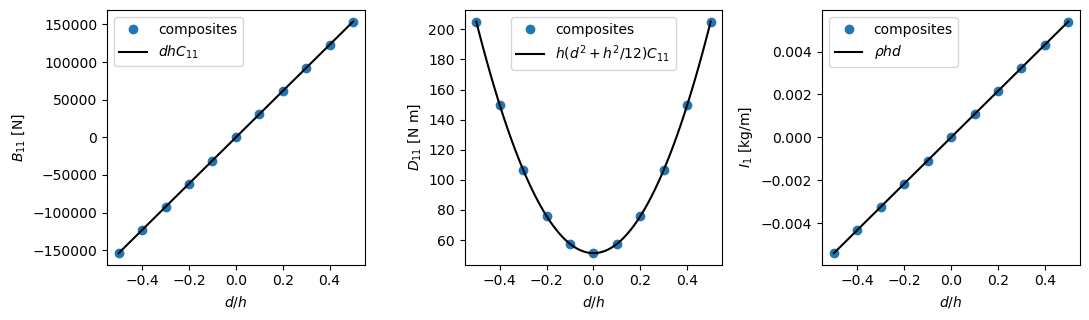

quantity                                 composites      reference rel. diff.
offset 0: intrhoz (scale rho h^2)      0.000000e+00   0.000000e+00    0.0e+00
offset 0: intrhoz3 (scale rho h^4)     0.000000e+00   0.000000e+00    0.0e+00
offset 0: max |Bij| (scale A11 h)      0.000000e+00   0.000000e+00    0.0e+00
A55 at d = h/2 vs d = 0                4.487179e+07   4.487179e+07    0.0e+00


In [4]:
offsets = np.linspace(-h/2, h/2, 11)
lams = [isotropic_plate(thickness=h, E=E, nu=nu, offset=di, rho=rho)
        for di in offsets]
dd = np.linspace(-h/2, h/2, 101)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
ax[0].plot(offsets/h, [l.B11 for l in lams], 'o', label='composites')
ax[0].plot(dd/h, dd*h*C[0, 0], 'k-', label='$d h C_{11}$')
ax[0].set_ylabel('$B_{11}$ [N]')
ax[1].plot(offsets/h, [l.D11 for l in lams], 'o', label='composites')
ax[1].plot(dd/h, h*(dd**2 + h**2/12)*C[0, 0], 'k-',
           label='$h (d^2 + h^2/12) C_{11}$')
ax[1].set_ylabel('$D_{11}$ [N m]')
ax[2].plot(offsets/h, [l.intrhoz for l in lams], 'o', label='composites')
ax[2].plot(dd/h, rho*h*dd, 'k-', label=r'$\rho h d$')
ax[2].set_ylabel(r'$I_1$ [kg/m]')
for a in ax:
    a.set_xlabel('$d/h$')
    a.legend()
fig.tight_layout()
plt.show()

lam0 = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)
print_table([
    ('offset 0: intrhoz (scale rho h^2)', lam0.intrhoz, 0., rho*h**2),
    ('offset 0: intrhoz3 (scale rho h^4)', lam0.intrhoz3, 0., rho*h**4),
    ('offset 0: max |Bij| (scale A11 h)', np.abs(lam0.B).max(), 0.,
     lam0.A11*h),
    ('A55 at d = h/2 vs d = 0', lams[-1].A55, lam0.A55),
])

## References

1. Vasiliev, V. V. and Morozov, E. V., Mechanics and Analysis of Composite Materials, Elsevier, Oxford, 2001.
2. Rohwer, K., Improved Transverse Shear Stiffnesses for Layered Finite Elements, DFVLR-FB 88-32, 1988.